# Chapter 8: Hierarchical Clustering

In [1]:
%reset
%matplotlib inline
low_memory=False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_blobs
from sklearn.metrics import mean_squared_error, mean_absolute_error, accuracy_score
from sklearn.datasets import load_digits
from sklearn.cluster import AgglomerativeClustering, KMeans
import scipy.cluster.hierarchy as shc
from scipy.stats import mode

## 8.1 Introduction & Motivation

Just like last time, we are passing our data and asking ourself the following question: within the given data, are there any **groups** or **clusters** of datapoints that belong together?

However, this time we will be having a look at hierarchical clustering. This method of clustering starts by looking at each individual datapoint and works it's way up until only one cluster remains. We can then define when to stop merging clusters and what the ideal amount of clusters is.

## 8.2 Problem Setting

Consider an automobile manufacturer that has created prototypes for a new vehicle. Prior to launching this new model, the manufacturer aims to identify which current vehicles on the market closely resemble the prototypes. This involves categorizing vehicles, determining which category is most similar to the new model, and identifying the models it will compete against.

The goal is to employ clustering techniques to identify the most distinct groups of vehicles. This will provide an overview of the current market and assist manufacturers in making informed decisions regarding the introduction of new models.

## 8.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Cars.csv")
df.head()

,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828,0.0
1,Acura,TL,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673,0.0
2,Acura,RL,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150,0.0
3,Audi,A4,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015,0.0
4,Audi,A6,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   manufact   117 non-null    str    
 1   model      117 non-null    str    
 2   sales      117 non-null    float64
 3   resale     117 non-null    float64
 4   type       117 non-null    float64
 5   price      117 non-null    float64
 6   engine_s   117 non-null    float64
 7   horsepow   117 non-null    float64
 8   wheelbas   117 non-null    float64
 9   width      117 non-null    float64
 10  length     117 non-null    float64
 11  curb_wgt   117 non-null    float64
 12  fuel_cap   117 non-null    float64
 13  mpg        117 non-null    float64
 14  lnsales    117 non-null    float64
 15  partition  117 non-null    float64
dtypes: float64(14), str(2)
memory usage: 14.8 KB


#### Question 1: Try and plot a heatmap to further explore the data. There will be two columns you will not be able to plot. Drop them from the heatmap, but do not drop them from your dataframe as we will be needing them later. You can also store them in a seperate dataframe if you wish.

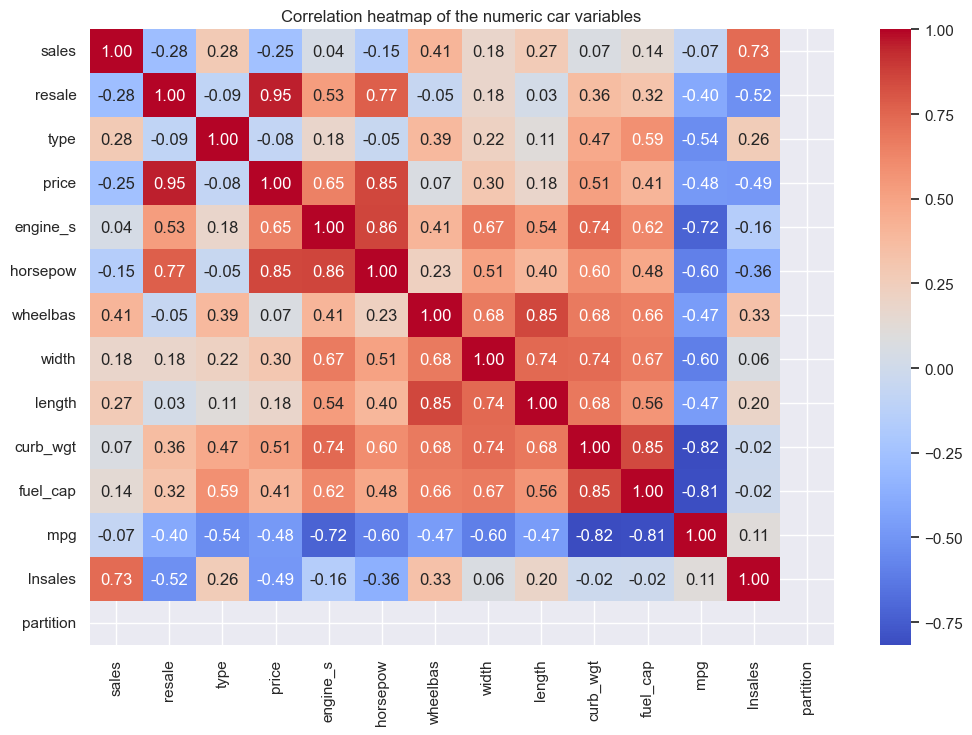

In [4]:
label_df = df[["manufact", "model"]]
numeric_df = df.drop(columns=["manufact", "model"])

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap of the numeric car variables")
plt.show()

#### Question 2: You will notice one column who acts different thant what we are used to. Why is this? Can we use this column? If not, drop the column.

In [5]:
# 'partition' behaves differently: it is constant in this dataset (only value 0).
# A constant column has no variance, so it cannot help to separate cars into clusters.
# We therefore remove it from the data used for clustering.
print(df["partition"].value_counts())

model_df = df.drop(columns=["manufact", "model", "partition"])

print("\n-----\n\nColumns used for clustering:")
print(model_df.columns.tolist())

# Hierarchical clustering is distance-based, so scaling is important.
X_scaled = (model_df - model_df.mean()) / model_df.std()
X_scaled = X_scaled.values

random.seed(42)
np.random.seed(42)

partition
0.0    117
Name: count, dtype: int64

-----

Columns used for clustering:
['sales', 'resale', 'type', 'price', 'engine_s', 'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap', 'mpg', 'lnsales']


## 8.4 Model Evaluation

#### Question 3: Create a dendogram of the model. Remember to exclude the two columns we are keeping to the side on your model. Instead, do some research on the parameters and use one or both of them as labels.

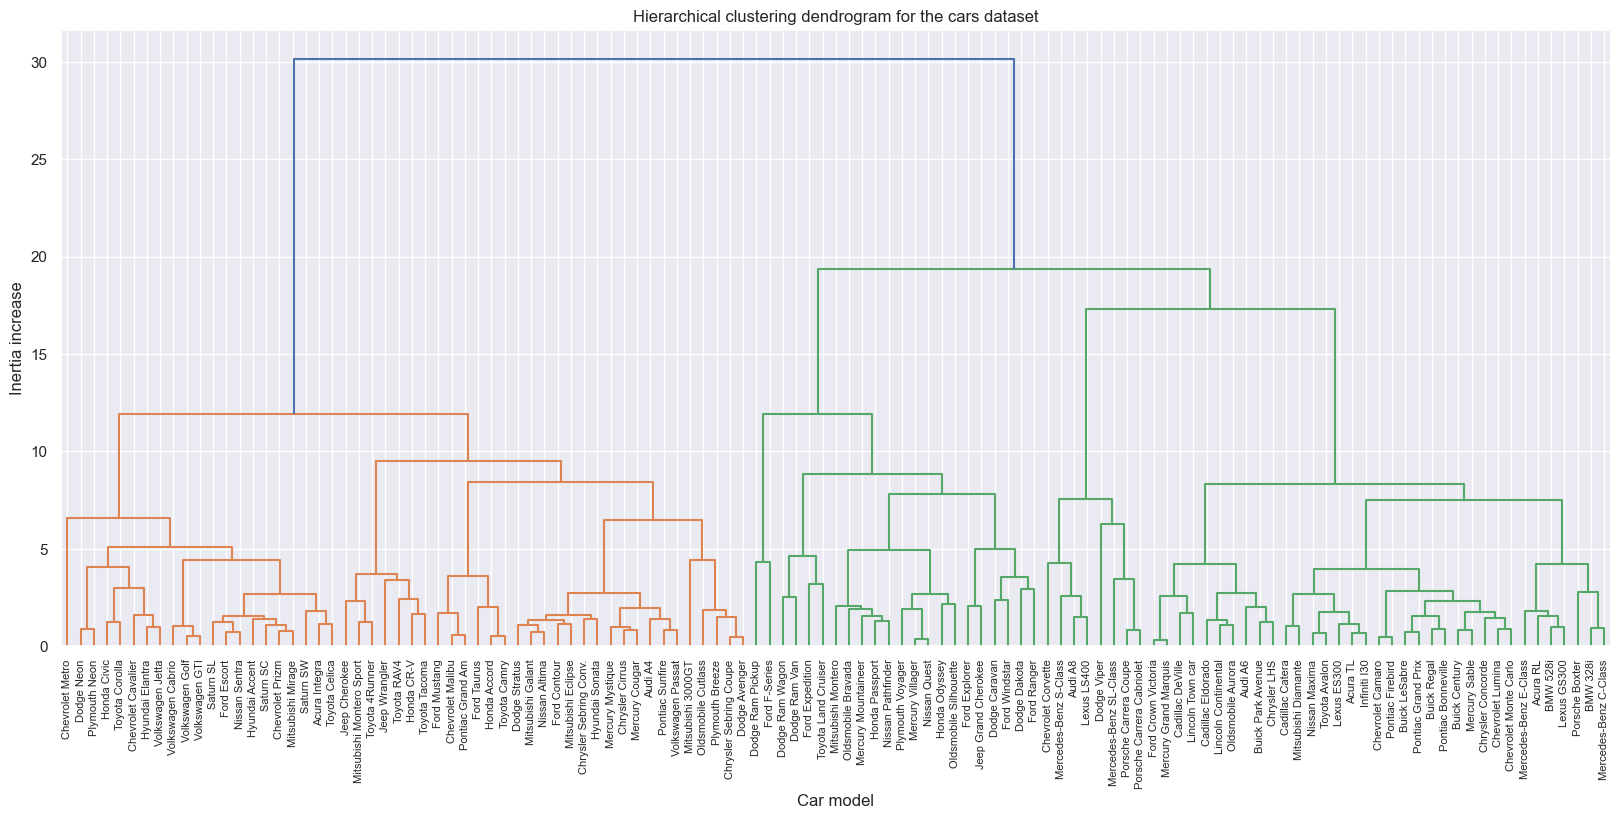

In [6]:
# Use manufacturer + model as readable labels in the dendrogram.
car_labels = (df["manufact"] + " " + df["model"]).tolist()

Z = shc.linkage(X_scaled, method="ward")

plt.figure(figsize=(20, 8))
shc.dendrogram(Z, labels=car_labels, leaf_rotation=90, leaf_font_size=8, color_threshold=None)
plt.title("Hierarchical clustering dendrogram for the cars dataset")
plt.xlabel("Car model")
plt.ylabel("Inertia increase")
plt.show()


#### Question 4: Think about the proces behind merging two clusters. By looking at the dendrogram, what would you think is a good amount of clusters? Why?

Een goede visuele keuze is **4 clusters**. In het dendrogram is er een duidelijke verticale sprong te zien voor de laatste grote samenvoegingen. Door in die opening horizontaal te knippen, blijven er vier groepen over. Bij minder clusters zouden duidelijk verschillende auto’s worden samengevoegd, terwijl bij veel meer clusters vergelijkbare auto’s in kleinere groepen zouden worden opgesplitst, met het risico op overfitting.

#### Question 5: Calculate the best amount of clusters. Look back to the dendrogram. Does this amount make sense?

,clusters,ward_merge_distance
0,1,30.117
1,2,19.385
2,3,17.325
3,4,11.910
4,5,11.898
5,6,9.491
6,7,8.828
7,8,8.444
8,9,8.331
9,10,7.794


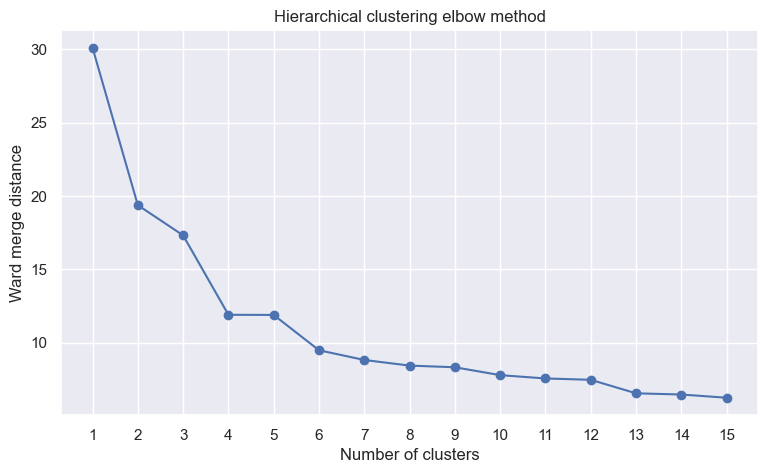

Best number of clusters by the hierarchical elbow method: 4


,number_of_cars,avg_price,avg_horsepower,avg_mpg,avg_curb_weight
hier_cluster,,,,,
1,52,16.929981,137.307692,26.942308,2.820077
2,22,25.861182,185.181818,19.363636,4.038045
3,8,66.215625,321.500000,20.750000,3.592750
4,35,30.268571,212.114286,23.680000,3.562600


In [7]:
merge_distances = Z[:, 2][::-1]
cluster_counts = np.arange(1, len(merge_distances) + 1)

elbow_df = pd.DataFrame({
    "clusters": cluster_counts[:15],
    "ward_merge_distance": np.round(merge_distances[:15], 3)
})
display(elbow_df)

plt.figure(figsize=(9, 5))
plt.plot(cluster_counts[:15], merge_distances[:15], marker="o")
plt.xticks(cluster_counts[:15])
plt.xlabel("Number of clusters")
plt.ylabel("Ward merge distance")
plt.title("Hierarchical clustering elbow method")
plt.show()

print("Best number of clusters by the hierarchical elbow method:", 4)

# Create final hierarchical cluster labels.
df["hier_cluster"] = shc.fcluster(Z, t=4, criterion="maxclust")

cluster_summary = (
    df.groupby("hier_cluster")
      .agg(
          number_of_cars=("model", "count"),
          avg_price=("price", "mean"),
          avg_horsepower=("horsepow", "mean"),
          avg_mpg=("mpg", "mean"),
          avg_curb_weight=("curb_wgt", "mean")
      )
)
cluster_summary

#### Question 6: Draw a line on the dendrogram to visualize the amount of clusters you have found. Do these groups make sense? Are the amount of cars in each cluster balanced? Elaborate.

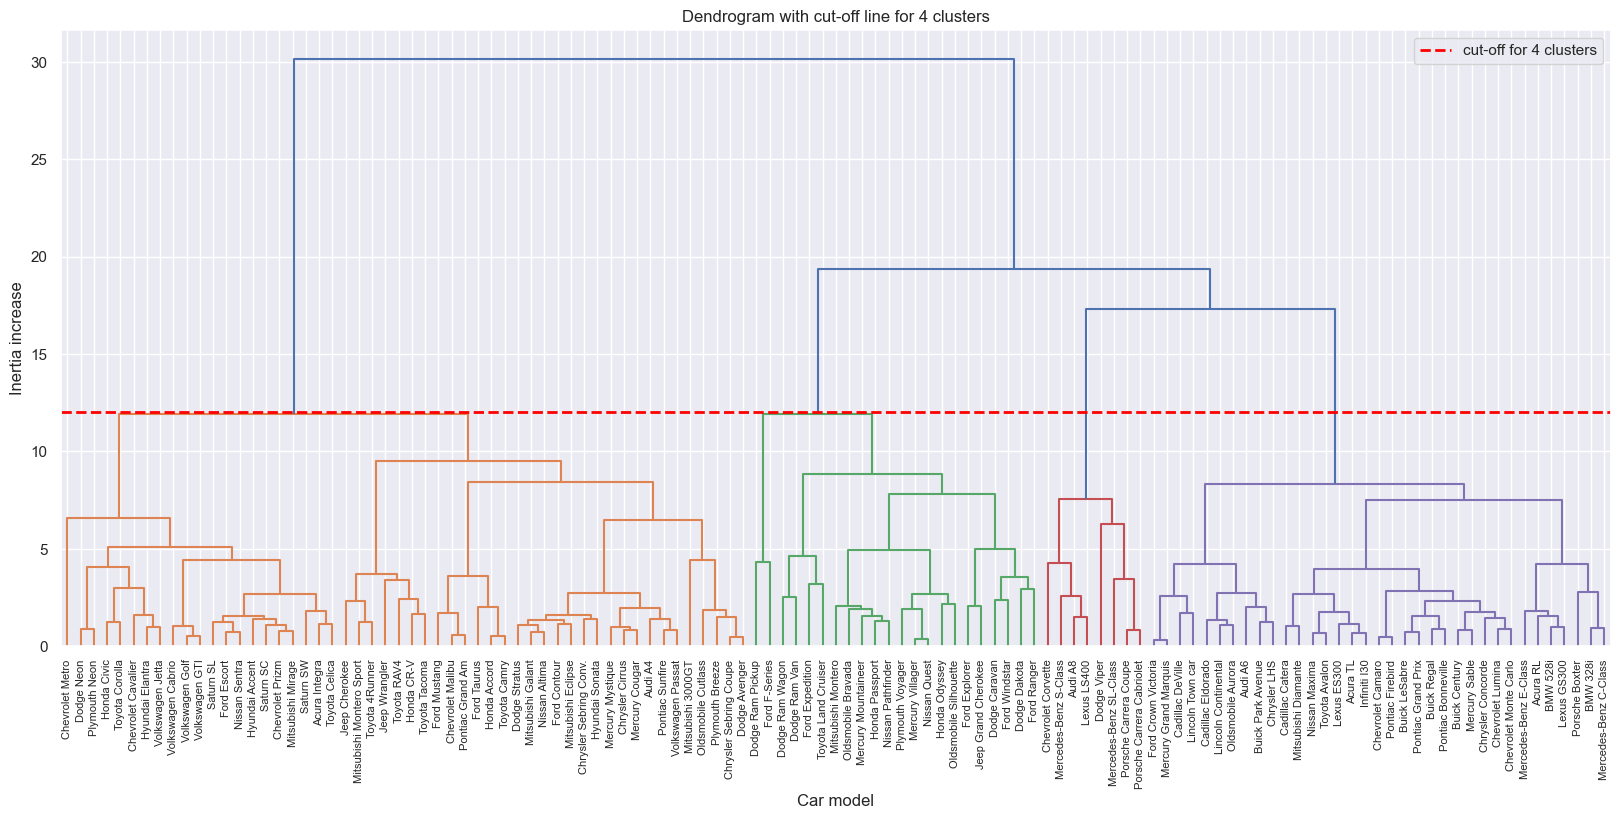

Cars per hierarchical cluster:
hier_cluster
1    52
2    22
3     8
4    35
Name: count, dtype: int64


,number_of_cars,avg_price,avg_horsepower,avg_mpg,avg_curb_weight
hier_cluster,,,,,
1,52,16.929981,137.307692,26.942308,2.820077
2,22,25.861182,185.181818,19.363636,4.038045
3,8,66.215625,321.500000,20.750000,3.592750
4,35,30.268571,212.114286,23.680000,3.562600


In [8]:
# A cut-off around 12 gives 4 clusters for this dataset.
cutoff = 12

plt.figure(figsize=(20, 8))
shc.dendrogram(Z, labels=car_labels, leaf_rotation=90, leaf_font_size=8, color_threshold=cutoff)
plt.axhline(y=cutoff, color="red", linestyle="--", linewidth=2, label="cut-off for 4 clusters")
plt.title("Dendrogram with cut-off line for 4 clusters")
plt.xlabel("Car model")
plt.ylabel("Inertia increase")
plt.legend()
plt.show()

print("Cars per hierarchical cluster:")
cluster_counts_hier = df["hier_cluster"].value_counts().sort_index()
print(cluster_counts_hier)

display(cluster_summary)

Conclusie:
De groepen zijn logisch, omdat auto’s zijn ingedeeld op basis van vergelijkbare numerieke kenmerken, zoals prijs, pk’s, brandstofverbruik en gewicht.
De clusters zijn niet perfect evenwichtig, maar dat is normaal: clustering moet de structuur in de gegevens weerspiegelen en mag geen gelijke groepsgroottes afdwingen.

## 8.4 Exercises

#### Question 1: See section 8.3
#### Question 2: See section 8.3
#### Question 3: See section 8.3
#### Question 4: See section 8.3
#### Question 5: See section 8.3
#### Question 6: See section 8.3
#### Question 7: Consider the cars dataset. Which clustering method would you prefer? Why?

Voor deze dataset geef ik de voorkeur aan **Ward hierarchical clustering** als eerste keuze.

Redenen:
1. De dataset is klein genoeg om duidelijk te kunnen inspecteren met een dendrogram.
2. Ward-linkage past bij de uitleg van de cursus: het voegt clusters samen door de toename in de variantie binnen clusters te minimaliseren.
3. Het dendrogram maakt het makkelijker om uit te leggen waarom 4 clusters een goede afbakening is.

K-means is ook mogelijk, maar vereist dat k vooraf wordt gekozen en geeft minder visueel inzicht in hoe de auto's stap voor stap worden samengevoegd.

#### Question 8: Calculate the best amount of k for k means. Compare it to the one you calculated earlier. Is it the same or different? Why?

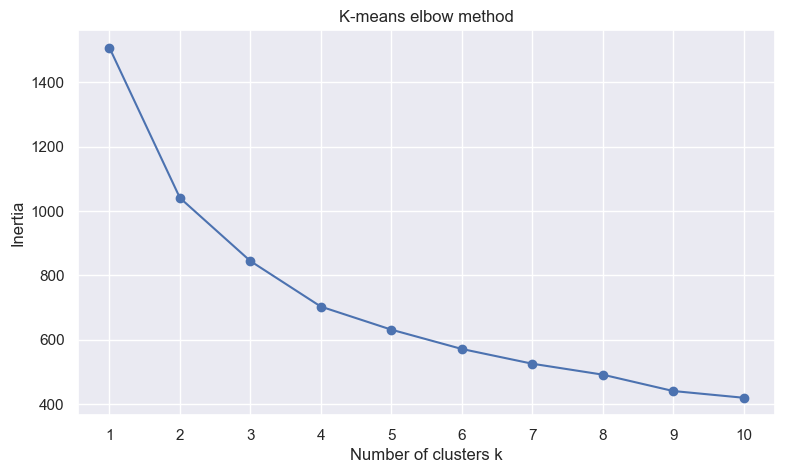

,k,inertia
0,1,1508.00
1,2,1041.04
2,3,844.69
3,4,703.01
4,5,631.31
5,6,571.24
6,7,525.39
7,8,491.36
8,9,440.46
9,10,419.48


Best number of clusters by the k-means elbow method: 4
Cars per k-means cluster:
kmeans_cluster
1     9
2    46
3    24
4    38
Name: count, dtype: int64

----

Comparison:
K-means gives the same best number of clusters as hierarchical clustering.


In [9]:
inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(range(1, 11)), inertias, marker="o")
plt.xticks(list(range(1, 11)))
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("K-means elbow method")
plt.show()

kmeans_elbow_df = pd.DataFrame({
    "k": list(range(1, 11)),
    "inertia": np.round(inertias, 2)
})
display(kmeans_elbow_df)

# Simple elbow calculation: point with the largest distance to the line between k=1 and k=10.
points = np.column_stack([list(range(1, 11)), inertias])
start = points[0]
end = points[-1]
line_vector = end - start

distances_to_line = np.abs(line_vector[0] * (start[1] - points[:, 1]) - (start[0] - points[:, 0]) * line_vector[1]) / np.sqrt(line_vector[0]**2 + line_vector[1]**2)

best_kmeans_k = int(list(range(1, 11))[np.argmax(distances_to_line)])
print("Best number of clusters by the k-means elbow method:", best_kmeans_k)

kmeans_final = KMeans(n_clusters=best_kmeans_k, random_state=42, n_init=10)
df["kmeans_cluster"] = kmeans_final.fit_predict(X_scaled) + 1

print("Cars per k-means cluster:")
print(df["kmeans_cluster"].value_counts().sort_index())

print("\n----\n\nComparison:")
if best_kmeans_k == 4:
    print("K-means gives the same best number of clusters as hierarchical clustering.")
else:
    print("K-means gives a different best number of clusters than hierarchical clustering.")